# Homework for Module 2
Date: 2026/09/28

by Jayon Lihm

target variable: `fuel_efficiency_mpg`

x variables: `engine_displacement`, `horsepower`, `vehicle_weight`, `model_year`, `fuel_efficiency_mpg`

In [1]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

--2026-09-28 13:52:44--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv.1’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.1s    

2026-09-28 13:52:44 (5.25 MB/s) - ‘car_fuel_efficiency_2026.csv.1’ saved [635180/635180]



In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

## Data import

In [4]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

## EDA

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

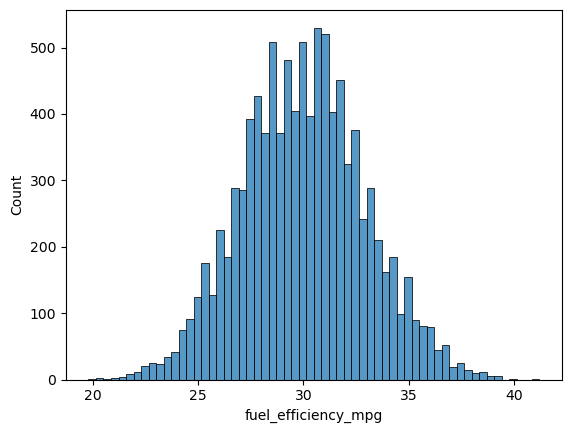

In [6]:
sns.histplot(df['fuel_efficiency_mpg'])

## Question 1

In [7]:
df[base].isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

## Question 2

In [9]:
df['horsepower'].median()

np.float64(254.0)

## Prepare and split datset

In [10]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

## Question 3 - impute with 0 or with mean

In [11]:
def prepare_X_with0(df):
    df2 = df.copy()
    X = df2[base].fillna(0).values
    return X

def prepare_X_withMean(df, horsepower_impute):
    df2 = df.copy()
    df2 = df2[base]
    df2['horsepower'] = df2['horsepower'].fillna( horsepower_impute )
    X = df2[base].values
    return X

In [12]:
base

['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

In [13]:
X_train_with_0 = prepare_X_with0(df_train)

horsepower_mean_train = df_train['horsepower'].mean()
X_train_with_mean = prepare_X_withMean(df_train, horsepower_mean_train)

y_train = np.array( df_train['fuel_efficiency_mpg'] )
y_val = np.array( df_val['fuel_efficiency_mpg'] )
y_test = np.array( df_test['fuel_efficiency_mpg'] )

In [14]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack( [ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

In [15]:
w_train_with_0 = train_linear_regression(X_train_with_0, y_train)
w0 = w_train_with_0[0]
w = w_train_with_0[1]

X_val_with_0 = prepare_X_with0(df_val)
y_val_pred_with_0 = w0 + X_val_with_0.dot(w)

In [16]:
w_train_with_mean = train_linear_regression(X_train_with_mean, y_train)
w0 = w_train_with_mean[0]
w = w_train_with_mean[1]

X_val_with_mean = prepare_X_withMean(df_val, horsepower_mean_train)
y_val_pred_with_mean = w0 + X_val_with_mean.dot(w)

In [17]:
def RMSE(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [18]:
print(RMSE(y_val, y_val_pred_with_0))


2.2052931947544785


In [19]:
print(RMSE(y_val, y_val_pred_with_mean))


2.2018174845686254


## Question 4 - with regularization

In [20]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack( [ ones, X ] )
    XTX = X.T.dot(X)
    XTX = XTX + np.eye(XTX.shape[0]) * r
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

In [22]:
rmse_min = np.inf
r_min= np.nan
X_val_with_0 = prepare_X_with0(df_val)
y_val = np.array(df_val['fuel_efficiency_mpg'])

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train_with_0, y_train, r=r)
    y_val_pred_with_0 = w0 + X_val_with_0.dot(w)
    val_rmse = RMSE(y_val, y_val_pred_with_0)
    #print("r=", r, "--> score=", val_rmse)
    print("r=", r, "--> score=", round(val_rmse, 4))
    if val_rmse < rmse_min:
        rmse_min = val_rmse
        r_min = r

print("smallest RMSE")
print(r_min, rmse_min)

r= 0 --> score= 2.2053
r= 0.01 --> score= 2.2058
r= 0.1 --> score= 2.2241
r= 1 --> score= 2.3492
r= 5 --> score= 2.4094
r= 10 --> score= 2.4195
r= 100 --> score= 2.4292
smallest RMSE
0 2.2052931947544785


## Question 5 - different seed numbers

In [23]:
def split_dataset(df, seed):
    np.random.seed(seed)
    np.random.shuffle(idx)
    df_train = df.iloc[ idx[:n_train] ]
    df_val = df.iloc[ idx[n_train:(n_val+n_train)] ]
    df_test = df.iloc[ idx[(n_val+n_train):] ]

    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    return df_train, df_val, df_test

In [26]:
seed_values = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmse_list = []
for s in seed_values:
    df_train, df_val, df_test = split_dataset(df, s)
    y_train = np.array( df_train['fuel_efficiency_mpg'] )
    y_val = np.array( df_val['fuel_efficiency_mpg'] )
    y_test = np.array( df_test['fuel_efficiency_mpg'] )

    ## prepare X
    X_train_with_0 = prepare_X_with0(df_train)
    w0, w = train_linear_regression(X_train_with_0, y_train)
    
    X_val_with_0 = prepare_X_with0(df_val)
    y_val_pred_with_0 = w0 + X_val_with_0.dot(w)
    val_rmse = RMSE(y_val, y_val_pred_with_0)
    print("seed=", s, "--> score=", round(val_rmse, 3))
    rmse_list.append(val_rmse)
    if val_rmse < rmse_min:
        rmse_min = val_rmse
        s_min = s

print("min rmse seed=", s_min, "--> min rmse=", round(rmse_min, 3))

seed= 0 --> score= 2.25
seed= 1 --> score= 2.149
seed= 2 --> score= 2.212
seed= 3 --> score= 2.179
seed= 4 --> score= 2.216
seed= 5 --> score= 2.222
seed= 6 --> score= 2.16
seed= 7 --> score= 2.267
seed= 8 --> score= 2.164
seed= 9 --> score= 2.189
min rmse seed= 1 --> min rmse= 2.149


In [27]:
round(np.std(rmse_list), 3)

np.float64(0.037)

## Question 6 - RMSE with regularization

In [31]:
df_train, df_val, df_test = split_dataset(df, seed=9)

In [29]:
df_comb = pd.concat([df_train, df_val])

X_comb_with_0 = prepare_X_with0(df_comb)
y_comb = np.array(df_comb['fuel_efficiency_mpg'])

In [32]:
w0, w = train_linear_regression_reg(X_comb_with_0, y_comb, r=0.001)

X_test_with_0 = prepare_X_with0(df_val)
y_test = np.array(df_val['fuel_efficiency_mpg'])
y_test_pred = w0 + X_test_with_0.dot(w)

RMSE(y_test, y_test_pred)

np.float64(2.2218474999440123)